# GBT Modelling — Rental Price Prediction

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 130)
pd.set_option('display.max_rows', 130)

RANDOM_STATE = 42

df = pd.read_parquet('rentals_final.parquet')
print('shape:', df.shape)
df.head()

shape: (12316, 120)


,lat,lon,listing_id,suburb,weekly_rent,date_listed,bedrooms,bathrooms,carspaces,property_type,feat_built_in_wardrobes,feat_heating,feat_dishwasher,feat_secure_parking,feat_internal_laundry,feat_air_conditioning,feat_balcony___deck,feat_gas,feat_floorboards,feat_bath,feat_intercom,feat_ensuite,feat_fully_fenced,feat_study,feat_furnished,feat_split_system_air_conditioning,feat_pets_allowed,feat_close_to_shops,feat_split_system_heating,feat_close_to_transport,feat_close_to_schools,feat_remote_garage,feat_shed,feat_ducted_heating,feat_garden___courtyard,feat_gym,feat_outdoor_entertainment_area,feat_balcony,feat_broadband_internet_access,feat_alarm_system,feat_swimming_pool,feat_courtyard,feat_solar_panels,feat_fireplaces,feat_pool_spa_count_0,feat_bathtub,feat_ensuites,feat_carpeted,feat_gas_appliances,feat_evaporative_cooling,feat_openable_windows,feat_broadband,feat_rumpus_room,feat_ducted_cooling,feat_broadband_internet_available,feat_city_views,feat_gas_heating,feat_deck,feat_laundry,feat_air_conditioner,feat_separate_dining_room,feat_double_glazed_windows,listed_year,listed_month,dist_to_cbd_km_driving,nearest_sports_rec_facility_id,sports_rec_road_distance_m,sports_rec_duration_s,sports_rec_is_confirmed,nearest_shopping_centre_facility_id,shopping_centre_road_distance_m,shopping_centre_duration_s,shopping_centre_is_confirmed,nearest_medical_doctors_facility_id,medical_doctors_road_distance_m,medical_doctors_duration_s,medical_doctors_is_confirmed,nearest_medical_clinic_facility_id,medical_clinic_road_distance_m,medical_clinic_duration_s,medical_clinic_is_confirmed,nearest_hospital_facility_id,hospital_road_distance_m,hospital_duration_s,hospital_is_confirmed,nearest_park_reserve_facility_id,park_reserve_road_distance_m,park_reserve_duration_s,park_reserve_is_confirmed,nearest_park_national_facility_id,park_national_road_distance_m,park_national_duration_s,park_national_is_confirmed,nearest_park_local_facility_id,park_local_road_distance_m,park_local_duration_s,park_local_is_confirmed,nearest_school_primary_facility_id,school_primary_road_distance_m,school_primary_duration_s,school_primary_is_confirmed,nearest_school_secondary_facility_id,school_secondary_road_distance_m,school_secondary_duration_s,school_secondary_is_confirmed,nearest_train_stations_PTV_facility_id,train_stations_PTV_road_distance_m,train_stations_PTV_duration_s,train_stations_PTV_is_confirmed,nearest_bus_stops_PTV_facility_id,bus_stops_PTV_road_distance_m,bus_stops_PTV_duration_s,bus_stops_PTV_is_confirmed,nearest_beaches_facility_id,beaches_road_distance_m,beaches_duration_s,beaches_is_confirmed,crime_rate,median_weekly_income,population
0,-37.830982,144.87091,16782629,SOUTH KINGSVILLE,460.0,2025-08-13,2.0,1.0,2.0,Apartment / Unit / Flat,1,1,0,1,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2025,8,10.02,HOBSON12954,406.54,61.09,True,MALL_way_211261191,2673.39,297.98,True,DOCTORS_way_514200333,2051.00,242.52,True,CLINIC_way_1037521510,2163.56,214.20,True,HOSPITAL_way_545775020,5301.66,586.63,True,PARK82,4953.02,597.91,True,PARK2376,7333.37,849.72,True,OSM_PARK_way_1561016516,43.98,10.55,True,1527.0,1060.45,167.21,True,1654.0,2873.23,323.09,True,15345,2144.18,246.90,True,40819.0,80.01,19.20,True,BEACH_way_34620304,6052.53,647.84,True,7959.260566,1598.0,20328.0
1,-37.826218,144.86755,17471867,SOUTH KINGSVILLE,400.0,2025-03-06,2.0,1.0,1.0,Apartment / Unit / Flat,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2025,3,10.36,HOBSON12954,747.72,82.82,True,MALL_way_211261191,2795.65,298.18,True,DOCTORS_node_7185766733,2448.99,260.39,True,CLINIC_node_4681170667,2827.06,282.86,True,HOSPITAL_way_276434644,6120.41,692.33,True,PARK82,5709.08,620.38,True,PARK2376,7674.56,871.45,True,OSM_PARK_way_143812906,336.57,61.54,True,1527.0,1401.63,188.94,True,1654.0,2995.49,323.28,True,15345,2485.36,268.63,True,40835.0,448.33,56.64,True,BEACH_way_712654263,6667.64,724.43,True,

In [2]:
# Dtypes, missingness, cardinality — full inventory before deciding anything
info = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'n_missing': df.isna().sum(),
    'pct_missing': (df.isna().mean() * 100).round(2),
    'n_unique': df.nunique(),
})
info

,dtype,n_missing,pct_missing,n_unique
lat,float64,0,0.0,10566
lon,float64,0,0.0,9828
listing_id,object,0,0.0,12316
suburb,object,0,0.0,644
weekly_rent,float64,0,0.0,371
date_listed,object,0,0.0,475
bedrooms,float64,0,0.0,12
bathrooms,float64,0,0.0,10
carspaces,float64,0,0.0,18
property_type,object,0,0.0,13


In [3]:
# Candidate target + structural columns: closer look
print('weekly_rent describe:')
print(df['weekly_rent'].describe())
print('\nweekly_rent missing:', df['weekly_rent'].isna().sum())

print('\nlisting_id: n rows =', len(df), ' n unique =', df['listing_id'].nunique(),
      ' n duplicated ids =', df['listing_id'].duplicated().sum())

print('\ndate_listed dtype:', df['date_listed'].dtype)
print('date_listed range:', df['date_listed'].min(), 'to', df['date_listed'].max())
print('\nlisted_year value counts:')
print(df['listed_year'].value_counts().sort_index())
print('\nlisted_month value counts:')
print(df['listed_month'].value_counts().sort_index())

print('\nsuburb: n unique =', df['suburb'].nunique())
print('property_type: n unique =', df['property_type'].nunique(), df['property_type'].unique())

weekly_rent describe:
count    12316.000000
mean       630.914907
std        294.480402
min        205.000000
25%        490.000000
50%        565.000000
75%        690.000000
max      10000.000000
Name: weekly_rent, dtype: float64

weekly_rent missing: 0

listing_id: n rows = 12316  n unique = 12316  n duplicated ids = 0

date_listed dtype: object
date_listed range: 2012-06-09 to 2025-09-09

listed_year value counts:
listed_year
2012        2
2013       20
2014        2
2016        5
2017        4
2018        6
2019        7
2020        7
2021       17
2022       29
2023       62
2024      217
2025    11938
Name: count, dtype: int64

listed_month value counts:
listed_month
1       34
2       90
3      103
4      143
5      262
6      521
7     1604
8     5501
9     3945
10      30
11      47
12      36
Name: count, dtype: int64

suburb: n unique = 644
property_type: n unique = 13 ['Apartment / Unit / Flat' 'Townhouse' 'House' 'Duplex' 'Villa' 'Studio'
 'Block of Units' 'Farm' 'New Hou

## Data inventory 

- **Data:** 12,316 rows × 120 cols; zero missing values 
- **Target:** `weekly_rent`, continuous regression ($205–$10,000, median $565)
- **No duplicates:** `listing_id` is unique per row
- **Split:** time-based, since 97% of listings are from 2025 (mostly Jul–Sep)
- **`suburb`:** 644 categories
- **Drop:** constant `*_is_confirmed` columns and `nearest_*_facility_id` join keys
- **Caveat:** can't tell real zeros from backfilled defaults (`crime_rate`, `median_weekly_income`, `population`)

## Step 1 — Problem framing

- **Target:** `weekly_rent` (AUD/week), regression
- **Primary metric:** RMSE, in $/week. Penalizes large misses
- **Secondary metric, MAE:** robust check given the long right tail (max $10,000 vs median $565)
- **Secondary metric, MAPE:** typical % error, since rents span a wide range
- **Deferred:** decide on modelling `log(weekly_rent)` in Step 3, after inspecting the training-only distribution

## Step 2 — Train/test split (before EDA)

- **Split:** time-based, sort by `date_listed`, earliest 85% train, latest 15% test
- **Why:** mimics real use (predict new listings from history), no future leakage
- **Groups:** `listing_id` is unique, so no group-leakage concern

In [4]:
df['date_listed'] = pd.to_datetime(df['date_listed'])
df_sorted = df.sort_values('date_listed').reset_index(drop=True)

split_idx = int(len(df_sorted) * 0.85)
cutoff_date = df_sorted.loc[split_idx, 'date_listed']

train_df = df_sorted.iloc[:split_idx].copy()
test_df = df_sorted.iloc[split_idx:].copy()

print('cutoff date:', cutoff_date)
print('train shape:', train_df.shape, ' date range:', train_df['date_listed'].min(), 'to', train_df['date_listed'].max())
print('test shape :', test_df.shape, ' date range:', test_df['date_listed'].min(), 'to', test_df['date_listed'].max())
print('\ntest as % of total:', round(len(test_df) / len(df_sorted) * 100, 2))
print('\ntrain weekly_rent describe:')
print(train_df['weekly_rent'].describe())
print('\ntest weekly_rent describe:')
print(test_df['weekly_rent'].describe())

cutoff date: 2025-09-04 00:00:00
train shape: (10468, 120)  date range: 2012-06-09 00:00:00 to 2025-09-04 00:00:00
test shape : (1848, 120)  date range: 2025-09-04 00:00:00 to 2025-09-09 00:00:00

test as % of total: 15.0

train weekly_rent describe:
count    10468.000000
mean       633.854222
std        303.643832
min        205.000000
25%        490.000000
50%        562.000000
75%        695.000000
max      10000.000000
Name: weekly_rent, dtype: float64

test weekly_rent describe:
count    1848.000000
mean      614.265152
std       235.327619
min       220.000000
25%       490.000000
50%       570.000000
75%       675.000000
max      4000.000000
Name: weekly_rent, dtype: float64


- **Cutoff:** 2025-09-04
- **Train:** 10,468 rows 
- **Test:** 1,848 rows, only ~5 days (2025-09-04 to 2025-09-09) because listings cluster in 2025, not a bug
- **Target shift:** means $634 vs $614, medians $562 vs $570, no alarming drift

## Step 3 — EDA on training data only

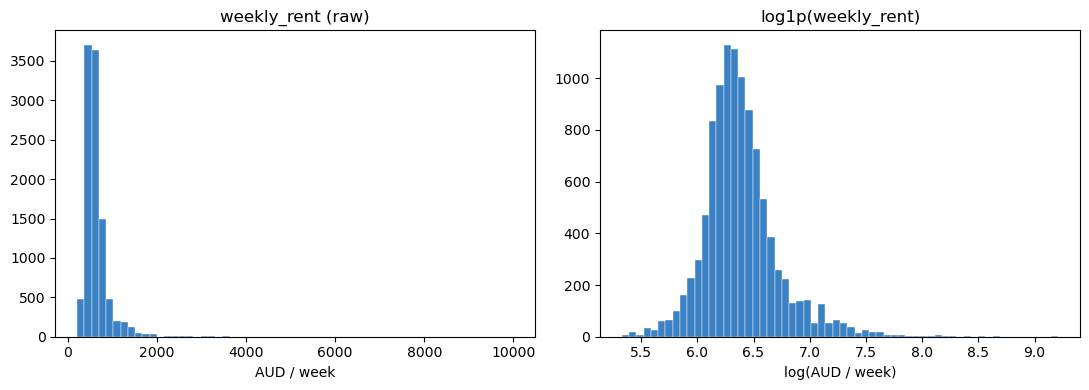

raw skew: 6.799176203231916
log1p skew: 1.094046701692184

top 10 highest weekly_rent rows in train:
               suburb            property_type  bedrooms  bathrooms  \
4326           TOORAK                    House       6.0        5.0   
5344           TOORAK                    House       4.0        4.0   
50           BRIGHTON  Apartment / Unit / Flat       5.0        4.0   
2913      SOUTH YARRA  Apartment / Unit / Flat       3.0        3.0   
9986         HAWTHORN                    House       5.0        5.0   
470   SOUTH MELBOURNE  Apartment / Unit / Flat       4.0        3.0   
116    PORT MELBOURNE                Townhouse       4.0        3.0   
5433         CREMORNE                    House       4.0        3.0   
1833      SOUTH YARRA                    House       3.0        2.0   
27           BRIGHTON                Townhouse       3.0        2.0   

      weekly_rent  
4326      10000.0  
5344       5750.0  
50         5000.0  
2913       4500.0  
9986       4500.0

In [5]:
from scipy.stats import skew

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(train_df['weekly_rent'], bins=60, color='#3B82C4', edgecolor='white', linewidth=0.3)
axes[0].set_title('weekly_rent (raw)')
axes[0].set_xlabel('AUD / week')

axes[1].hist(np.log1p(train_df['weekly_rent']), bins=60, color='#3B82C4', edgecolor='white', linewidth=0.3)
axes[1].set_title('log1p(weekly_rent)')
axes[1].set_xlabel('log(AUD / week)')
plt.tight_layout()
plt.show()

print('raw skew:', skew(train_df['weekly_rent']))
print('log1p skew:', skew(np.log1p(train_df['weekly_rent'])))
print('\ntop 10 highest weekly_rent rows in train:')
print(train_df.nlargest(10, 'weekly_rent')[['suburb', 'property_type', 'bedrooms', 'bathrooms', 'weekly_rent']])

- **Skew:** raw `weekly_rent` = 6.80, `log1p` = 1.09 (np.log1p(x) calculates the natural logarithm of 1 plus the input array)
- **Top-10 outliers:** luxury houses/apartments in Toorak, Brighton, South Yarra, Hawthorn; plausible, not errors (e.g. $10,000/week Toorak 6-bed/5-bath)
- **Decision:** train GBT on `log1p(weekly_rent)`
- **Evaluation:** back-transform with `expm1`, compute RMSE/MAE/MAPE in dollars
- **Why:** fixes skew, reduces leverage of extreme listings

In [ ]:
# Constant / near-zero-variance columns (candidates for removal)
nunique_train = train_df.nunique()
constant_cols = nunique_train[nunique_train == 1].index.tolist()
print('\nconstant columns in train:', constant_cols)

# Cardinality of key categoricals
cat_cols = ['suburb', 'property_type']
for c in cat_cols:
    print(f'\n{c}: {train_df[c].nunique()} unique values')
    print(train_df[c].value_counts().head(10))

columns with any missing values in train: 0



constant columns in train:

 ['sports_rec_is_confirmed', 'shopping_centre_is_confirmed', 'medical_doctors_is_confirmed', 'medical_clinic_is_confirmed', 'hospital_is_confirmed', 'park_reserve_is_confirmed', 'park_national_is_confirmed', 'park_local_is_confirmed', 'school_primary_is_confirmed', 'school_secondary_is_confirmed', 'train_stations_PTV_is_confirmed', 'beaches_is_confirmed']

suburb: 626 unique values
suburb
TARNEIT        269
SOUTHBANK      267
MELBOURNE      230
TRUGANINA      181
POINT COOK     180
WERRIBEE       179
SOUTH YARRA    179
FOOTSCRAY      152
CLAYTON        141
ST KILDA       139
Name: count, dtype: int64

property_type: 13 unique values
property_type
House                            5409
Apartment / Unit / Flat          3720
Townhouse                        1067
Studio                            171
New Apartments / Off the Plan      44
Villa                              22
Semi-Detached                      10
Acreage / Semi-Rural               10
New House & Land                    6
Blo

In [7]:
# Duplicate / near-duplicate row check (excluding listing_id and date_listed, which are identifiers/timestamps)
feature_cols_for_dup_check = [c for c in train_df.columns if c not in ('listing_id', 'date_listed')]
exact_dupes = train_df.duplicated(subset=feature_cols_for_dup_check).sum()
print('exact duplicate rows (excluding listing_id/date_listed):', exact_dupes)

# Same property attributes + same suburb + same rent, different listing_id/date -> likely re-listing of the same unit
relist_check_cols = ['suburb', 'bedrooms', 'bathrooms', 'carspaces', 'property_type', 'weekly_rent', 'lat', 'lon']
near_dupes = train_df.duplicated(subset=relist_check_cols).sum()
print('rows matching another row on suburb/beds/baths/cars/type/rent/lat/lon (possible re-listings):', near_dupes)

exact duplicate rows (excluding listing_id/date_listed): 70
rows matching another row on suburb/beds/baths/cars/type/rent/lat/lon (possible re-listings): 187


In [ ]:
# Check: does the same physical property (same lat/lon) appear in both train and test?
# Risk: the model could memorize a re-listed property instead of generalizing
# Why listing_id misses it: it's unique per ad, but a re-listed property keeps its lat/lon

train_latlon = set(zip(train_df['lat'], train_df['lon']))
test_latlon = set(zip(test_df['lat'], test_df['lon']))
overlap = train_latlon & test_latlon
print('unique lat/lon pairs in train:', len(train_latlon))
print('unique lat/lon pairs in test:', len(test_latlon))
print('lat/lon pairs appearing in BOTH train and test:', len(overlap))
print('as % of test rows:', round(test_df.set_index(["lat","lon"]).index.isin(overlap).mean() * 100, 2))

unique lat/lon pairs in train: 9388
unique lat/lon pairs in test: 1788
lat/lon pairs appearing in BOTH train and test: 170
as % of test rows: 11.53


**EDA findings and decisions:**

- **Missing values:** none in train, nothing to impute
- **Constant columns:** 12 `*_is_confirmed` flags (all True), drop
- **`suburb`:** 626 unique in train vs 644 overall, so 18 appear only in test. Encoding must handle unseen categories (native tree categoricals or unseen → NaN/other), not a fixed one-hot vocabulary
- **Leakage:** none found; `listed_year`/`listed_month` come from `date_listed`, not post-outcome info
- **Duplicates:** drop 70 exact duplicates in train; keep 187 near-duplicates as genuine re-listings
- **Cross-split overlap:** 170 lat/lon pairs (11.5% of test rows) also in train. Realistic for deployment, but may inflate the test score through partial memorization
- **Caveat:** carried to final evaluation, not corrected; a property-level group split would abandon the temporal realism

## Step 4 — Feature engineering

**Plan:**
- **Drop rows:** 70 exact duplicates from train
- **Drop columns:** 12 constant `*_is_confirmed` flags, 12 `nearest_*_facility_id` join keys (signal already in distance/duration columns), `listing_id`, raw `date_listed`
- **`amenity_count`:** sum of the 52 `feat_*` binary flags
- **`days_since_start`:** days since train's minimum date, anchor fixed from train only, so no test leakage
- **Categoricals:** `suburb` and `property_type` as pandas `category`, categories fixed from train; the 18 test-only suburbs become NaN, handled natively by XGBoost
- **Missing values:** left as NaN, no imputation

In [9]:
from pandas.api.types import CategoricalDtype

# 1. Drop exact duplicates from train only
train_df = train_df.drop_duplicates(subset=feature_cols_for_dup_check).reset_index(drop=True)
print('train shape after dropping exact duplicates:', train_df.shape)

# 2. Columns to drop entirely
facility_id_cols = [c for c in df.columns if c.startswith('nearest_')]
drop_cols = constant_cols + facility_id_cols + ['listing_id']
print('\ndropping', len(drop_cols), 'columns:', drop_cols)

feat_cols = [c for c in df.columns if c.startswith('feat_')]
print('\namenity flags being summed:', len(feat_cols))

MIN_DATE = train_df['date_listed'].min()
print('reference min date (train only):', MIN_DATE)

def engineer_features(raw_df, min_date, suburb_categories, property_type_categories):
    d = raw_df.drop(columns=drop_cols).copy()
    d['amenity_count'] = raw_df[feat_cols].sum(axis=1)
    d['days_since_start'] = (raw_df['date_listed'] - min_date).dt.days
    d = d.drop(columns=['date_listed'])
    d['suburb'] = d['suburb'].astype(CategoricalDtype(categories=suburb_categories))
    d['property_type'] = d['property_type'].astype(CategoricalDtype(categories=property_type_categories))
    return d

suburb_categories = sorted(train_df['suburb'].unique())
property_type_categories = sorted(train_df['property_type'].unique())

X_train_full = engineer_features(train_df, MIN_DATE, suburb_categories, property_type_categories)
X_test = engineer_features(test_df, MIN_DATE, suburb_categories, property_type_categories)

y_train_full_raw = train_df['weekly_rent'].values
y_test_raw = test_df['weekly_rent'].values
y_train_full = np.log1p(y_train_full_raw)
y_test = np.log1p(y_test_raw)

X_train_full = X_train_full.drop(columns=['weekly_rent'])
X_test = X_test.drop(columns=['weekly_rent'])

print('\nX_train_full shape:', X_train_full.shape)
print('X_test shape:', X_test.shape)
print('\nunseen suburb categories in test -> NaN count:', X_test['suburb'].isna().sum(), '/', len(X_test))
print('dtypes of engineered categoricals:', X_train_full['suburb'].dtype, X_train_full['property_type'].dtype)
X_train_full.dtypes.value_counts()

train shape after dropping exact duplicates: (10398, 120)

dropping 26 columns: ['sports_rec_is_confirmed', 'shopping_centre_is_confirmed', 'medical_doctors_is_confirmed', 'medical_clinic_is_confirmed', 'hospital_is_confirmed', 'park_reserve_is_confirmed', 'park_national_is_confirmed', 'park_local_is_confirmed', 'school_primary_is_confirmed', 'school_secondary_is_confirmed', 'train_stations_PTV_is_confirmed', 'beaches_is_confirmed', 'nearest_sports_rec_facility_id', 'nearest_shopping_centre_facility_id', 'nearest_medical_doctors_facility_id', 'nearest_medical_clinic_facility_id', 'nearest_hospital_facility_id', 'nearest_park_reserve_facility_id', 'nearest_park_national_facility_id', 'nearest_park_local_facility_id', 'nearest_school_primary_facility_id', 'nearest_school_secondary_facility_id', 'nearest_train_stations_PTV_facility_id', 'nearest_bus_stops_PTV_facility_id', 'nearest_beaches_facility_id', 'listing_id']

amenity flags being summed: 52
reference min date (train only): 2012-06

int32       54
float64     35
int64        2
category     1
category     1
bool         1
Name: count, dtype: int64

## Step 5 — Baseline model

- **Model:** plain linear regression, one-hot categoricals, `log1p` target, untuned
- **Purpose:** a floor the GBT must clear, not expected to win
- **CV:** `TimeSeriesSplit`, not random `KFold`, so the score is comparable to the later GBT CV
- **Metrics:** back-transformed with `expm1`, reported in dollars (RMSE/MAE/MAPE per Step 1)

In [10]:
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error, mean_absolute_error

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

cat_features = ['suburb', 'property_type']
num_features = [c for c in X_train_full.columns if c not in cat_features]

baseline_preprocess = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features),
    ('num', StandardScaler(), num_features),
])
baseline_pipe = Pipeline([
    ('prep', baseline_preprocess),
    ('lr', LinearRegression()),
])

N_SPLITS = 5
tscv = TimeSeriesSplit(n_splits=N_SPLITS)

fold_rmse, fold_mae, fold_mape = [], [], []
for fold, (tr_idx, val_idx) in enumerate(tscv.split(X_train_full)):
    X_tr, X_val = X_train_full.iloc[tr_idx], X_train_full.iloc[val_idx]
    y_tr_log, y_val_log = y_train_full[tr_idx], y_train_full[val_idx]

    baseline_pipe.fit(X_tr, y_tr_log)
    pred_log = baseline_pipe.predict(X_val)
    pred_dollars = np.expm1(pred_log)
    true_dollars = np.expm1(y_val_log)

    fold_rmse.append(rmse(true_dollars, pred_dollars))
    fold_mae.append(mean_absolute_error(true_dollars, pred_dollars))
    fold_mape.append(mape(true_dollars, pred_dollars))
    print(f'fold {fold}: train={len(tr_idx)} val={len(val_idx)}  RMSE=${fold_rmse[-1]:.1f}  MAE=${fold_mae[-1]:.1f}  MAPE={fold_mape[-1]:.1f}%')

print(f'\nBaseline linear regression — {N_SPLITS}-fold TimeSeriesSplit CV:')
print(f'RMSE: {np.mean(fold_rmse):.1f} +/- {np.std(fold_rmse):.1f}')
print(f'MAE : {np.mean(fold_mae):.1f} +/- {np.std(fold_mae):.1f}')
print(f'MAPE: {np.mean(fold_mape):.1f}% +/- {np.std(fold_mape):.1f}%')

fold 0: train=1733 val=1733  RMSE=$341.4  MAE=$141.1  MAPE=22.5%


fold 1: train=3466 val=1733  RMSE=$242.3  MAE=$99.1  MAPE=14.4%


fold 2: train=5199 val=1733  RMSE=$180.3  MAE=$88.7  MAPE=13.4%


fold 3: train=6932 val=1733  RMSE=$171.9  MAE=$81.4  MAPE=13.0%


fold 4: train=8665 val=1733  RMSE=$142.3  MAE=$76.3  MAPE=11.6%

Baseline linear regression — 5-fold TimeSeriesSplit CV:
RMSE: 215.6 +/- 70.8
MAE : 97.3 +/- 23.2
MAPE: 15.0% +/- 3.9%


- **Baseline (5 `TimeSeriesSplit` folds):** RMSE ≈ $216 ± $71, MAE ≈ $97 ± $23, MAPE ≈ 15.0% ± 3.9%
- **Trend:** RMSE improves fold 0 → 4 ($341 → $142) because later folds have more training history (fold 0 trains on only ~1,700 mostly pre-2024 rows)
- **Variance:** already wide for a simple model, so watch the GBT's CV spread in Step 9
- **Role:** this is the floor the GBT must beat

## Step 6 — Library choice and CV setup

- **Library:** XGBoost
- **Categoricals:** native handling via `enable_categorical=True` on the Step 4 `category` dtype, so no one-hot blow-up and no fold-dependent target encoding
- **Unseen categories:** become NaN at inference, which XGBoost routes natively
- **Fit:** ~10K rows × 94 features is well within XGBoost's range, with early stopping and SHAP support
- **Alternatives:** LightGBM/CatBoost not worth switching to
- **CV:** reuse the same 5-fold `TimeSeriesSplit` for every later step, so results stay comparable

In [11]:
# Verify the CV folds actually respect time order (no future dates leaking into a training fold)
dates = train_df['date_listed'].values
for fold, (tr_idx, val_idx) in enumerate(tscv.split(X_train_full)):
    print(f'fold {fold}: train dates {pd.Timestamp(dates[tr_idx].min())} -> {pd.Timestamp(dates[tr_idx].max())} '
          f'({len(tr_idx)} rows) | val dates {pd.Timestamp(dates[val_idx].min())} -> {pd.Timestamp(dates[val_idx].max())} ({len(val_idx)} rows)')
    assert dates[tr_idx].max() <= dates[val_idx].min(), 'leakage: train fold contains dates after validation fold start'
print('\nAll folds verified: every training fold ends before its validation fold begins.')

fold 0: train dates 2012-06-09 00:00:00 -> 2025-07-10 00:00:00 (1733 rows) | val dates 2025-07-11 00:00:00 -> 2025-08-06 00:00:00 (1733 rows)
fold 1: train dates 2012-06-09 00:00:00 -> 2025-08-06 00:00:00 (3466 rows) | val dates 2025-08-06 00:00:00 -> 2025-08-18 00:00:00 (1733 rows)
fold 2: train dates 2012-06-09 00:00:00 -> 2025-08-18 00:00:00 (5199 rows) | val dates 2025-08-18 00:00:00 -> 2025-08-26 00:00:00 (1733 rows)
fold 3: train dates 2012-06-09 00:00:00 -> 2025-08-26 00:00:00 (6932 rows) | val dates 2025-08-26 00:00:00 -> 2025-09-01 00:00:00 (1733 rows)
fold 4: train dates 2012-06-09 00:00:00 -> 2025-09-01 00:00:00 (8665 rows) | val dates 2025-09-01 00:00:00 -> 2025-09-04 00:00:00 (1733 rows)

All folds verified: every training fold ends before its validation fold begins.


- **Boundary:** at each fold edge, train-max and val-min share a calendar day (e.g. fold 1 on 2025-08-06)
- **Cause:** `date_listed` is daily resolution, so same-day listings split across the boundary
- **Impact:** minor artifact, not leakage; no validation date precedes any training date in its fold

## Step 7 — Initial GBT fit with early stopping

- **Fit:** initial XGBoost on the last CV fold (fold 4), which has the largest training set and the most recent validation slice
- **Setup:** `n_estimators` ceiling of 3000, early stopping on validation log-RMSE
- **Purpose:** confirm the pipeline works end-to-end (categoricals, log target, eval metric) and get a sane tree count
- **Not tuned:** Optuna search comes next

In [12]:
import xgboost as xgb
print('xgboost version:', xgb.__version__)

fold_splits = list(tscv.split(X_train_full))
last_tr_idx, last_val_idx = fold_splits[-1]

X_tr, X_val = X_train_full.iloc[last_tr_idx], X_train_full.iloc[last_val_idx]
y_tr, y_val = y_train_full[last_tr_idx], y_train_full[last_val_idx]

initial_model = xgb.XGBRegressor(
    n_estimators=3000,
    learning_rate=0.05,
    max_depth=6,
    enable_categorical=True,
    tree_method='hist',
    eval_metric='rmse',
    early_stopping_rounds=50,
    random_state=RANDOM_STATE,
)
initial_model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)

print('best_iteration:', initial_model.best_iteration)
print('best_score (log-RMSE):', initial_model.best_score)

pred_log = initial_model.predict(X_val, iteration_range=(0, initial_model.best_iteration + 1))
pred_dollars = np.expm1(pred_log)
true_dollars = np.expm1(y_val)
print(f'\nvalidation RMSE: ${rmse(true_dollars, pred_dollars):.1f}')
print(f'validation MAE : ${mean_absolute_error(true_dollars, pred_dollars):.1f}')
print(f'validation MAPE: {mape(true_dollars, pred_dollars):.1f}%')

xgboost version: 2.1.4


best_iteration: 164
best_score (log-RMSE): 0.1463992772862169

validation RMSE: $157.5
validation MAE : $70.6
validation MAPE: 10.3%


- **Initial fit (fold 4, untuned):** early stopping picked 164 trees (of the 3000 ceiling), log-RMSE 0.146
- **Metrics:** RMSE $157.5, MAE $70.6, MAPE 10.3%
- **Vs baseline (same fold):** MAE ($76.3) and MAPE (11.6%) already better, but RMSE slightly worse ($142.3 baseline)
- **Likely cause:** untuned depth/learning rate is too aggressive on a few hard cases
- **Pipeline:** confirmed working end-to-end (categoricals, log target, early stopping, back-transform)
- **Next:** Step 8 tuning should close the RMSE gap

## Step 8 — Hyperparameter tuning with Optuna

- **Search space:** `learning_rate`, `max_depth`, `min_child_weight`, `subsample`, `colsample_bytree`, `gamma`, `reg_alpha`, `reg_lambda`
- **Method:** Optuna TPE sampler
- **Objective:** mean log-RMSE across the same 5 `TimeSeriesSplit` folds
- **Early stopping:** inside each fold on its own validation slice, never the test set
- **Class weighting:** not applicable, this is regression

In [13]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    params = {
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'min_child_weight': trial.suggest_float('min_child_weight', 1e-2, 20, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'gamma': trial.suggest_float('gamma', 1e-3, 5.0, log=True),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
    }

    fold_scores = []
    for tr_idx, val_idx in fold_splits:
        X_tr, X_val = X_train_full.iloc[tr_idx], X_train_full.iloc[val_idx]
        y_tr, y_val = y_train_full[tr_idx], y_train_full[val_idx]

        model = xgb.XGBRegressor(
            n_estimators=2000,
            enable_categorical=True,
            tree_method='hist',
            eval_metric='rmse',
            early_stopping_rounds=50,
            random_state=RANDOM_STATE,
            **params,
        )
        model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
        fold_scores.append(model.best_score)

    return float(np.mean(fold_scores))

study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study.optimize(objective, n_trials=40, show_progress_bar=False)

print('best mean log-RMSE across folds:', study.best_value)
print('best params:')
for k, v in study.best_params.items():
    print(f'  {k}: {v}')

best mean log-RMSE across folds: 0.14062073337528297
best params:
  learning_rate: 0.010858139649237177
  max_depth: 9
  min_child_weight: 10.426301263645723
  subsample: 0.8133282561526441
  colsample_bytree: 0.7049486488938966
  gamma: 0.0022716611790582135
  reg_alpha: 0.03174939661606171
  reg_lambda: 0.11190513917714559


- **Best mean log-RMSE (5 folds):** 0.1406, consistent with an improvement over the untuned 0.146 (that was a single fold, so not directly comparable)
- **Best params:** `learning_rate` 0.0109, `max_depth` 9, `min_child_weight` 10.4, `subsample`/`colsample_bytree` ~0.7 to 0.8, light `reg_alpha`/`reg_lambda`
- **Caveat:** `learning_rate` (search floor 0.01) and `max_depth` (ceiling 10) landed near the edges, so the true optimum may lie outside the searched space
- **Verdict:** the 40-trial result is coherent (regularization not at its limits), good enough to proceed

## Step 9 — Full CV validation of the tuned model

In [14]:
best_params = study.best_params

tuned_fold_rmse, tuned_fold_mae, tuned_fold_mape, tuned_best_iters = [], [], [], []
for fold, (tr_idx, val_idx) in enumerate(fold_splits):
    X_tr, X_val = X_train_full.iloc[tr_idx], X_train_full.iloc[val_idx]
    y_tr, y_val = y_train_full[tr_idx], y_train_full[val_idx]

    model = xgb.XGBRegressor(
        n_estimators=2000,
        enable_categorical=True,
        tree_method='hist',
        eval_metric='rmse',
        early_stopping_rounds=50,
        random_state=RANDOM_STATE,
        **best_params,
    )
    model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)

    pred_log = model.predict(X_val, iteration_range=(0, model.best_iteration + 1))
    pred_dollars = np.expm1(pred_log)
    true_dollars = np.expm1(y_val)

    tuned_fold_rmse.append(rmse(true_dollars, pred_dollars))
    tuned_fold_mae.append(mean_absolute_error(true_dollars, pred_dollars))
    tuned_fold_mape.append(mape(true_dollars, pred_dollars))
    tuned_best_iters.append(model.best_iteration)
    print(f'fold {fold}: best_iter={model.best_iteration}  RMSE=${tuned_fold_rmse[-1]:.1f}  MAE=${tuned_fold_mae[-1]:.1f}  MAPE={tuned_fold_mape[-1]:.1f}%')

print(f'\nTuned XGBoost — {N_SPLITS}-fold TimeSeriesSplit CV:')
print(f'RMSE: {np.mean(tuned_fold_rmse):.1f} +/- {np.std(tuned_fold_rmse):.1f}  (CoV={np.std(tuned_fold_rmse)/np.mean(tuned_fold_rmse)*100:.1f}%)')
print(f'MAE : {np.mean(tuned_fold_mae):.1f} +/- {np.std(tuned_fold_mae):.1f}  (CoV={np.std(tuned_fold_mae)/np.mean(tuned_fold_mae)*100:.1f}%)')
print(f'MAPE: {np.mean(tuned_fold_mape):.1f}% +/- {np.std(tuned_fold_mape):.1f}%')
print(f'\nbest_iteration per fold: {tuned_best_iters}  (mean={np.mean(tuned_best_iters):.0f})')

fold 0: best_iter=521  RMSE=$170.4  MAE=$81.4  MAPE=11.8%


fold 1: best_iter=1056  RMSE=$228.2  MAE=$72.8  MAPE=9.9%


fold 2: best_iter=734  RMSE=$133.7  MAE=$65.9  MAPE=9.4%


fold 3: best_iter=916  RMSE=$112.8  MAE=$60.4  MAPE=9.1%


fold 4: best_iter=845  RMSE=$127.7  MAE=$61.9  MAPE=9.0%

Tuned XGBoost — 5-fold TimeSeriesSplit CV:
RMSE: 154.6 +/- 41.4  (CoV=26.8%)
MAE : 68.5 +/- 7.8  (CoV=11.3%)
MAPE: 9.8% +/- 1.0%

best_iteration per fold: [521, 1056, 734, 916, 845]  (mean=814)


- **Tuned XGBoost (5-fold CV):** RMSE $154.6 ± $41.4, MAE $68.5 ± $7.8, MAPE 9.8% ± 1.0%
- **Vs baseline:** better on every metric (RMSE $216→$155, MAE $97→$69, MAPE 15.0%→9.8%)
- **Fold variance:** RMSE CoV 26.8%, driven by fold 1 (RMSE $228 vs $113 to $171 elsewhere)
- **Cause:** fold 1's MAE ($72.8) and MAPE (9.9%) are in line, so it's a few large-dollar misses that RMSE amplifies, not general unreliability
- **Stability:** MAE (CoV 11.3%) and MAPE (~10%) are steady, the more reassuring read on typical-case performance
- **Follow-up:** check high-end listings in the Step 10 residual analysis
- **Trees:** `best_iteration` 521 to 1056 (mean 814), used to pick the final count in Step 12

## Step 10 — Calibration / error analysis

- **Method:** residual analysis using out-of-fold (OOF) predictions, since a confusion matrix doesn't apply to regression
- **Coverage:** 8,665 of 10,398 training rows get an OOF prediction; fold 0's training rows are never in a validation split, so they have none
- **Why OOF:** residuals reflect real CV behaviour, not an in-sample fit

In [15]:
oof_pred_dollars = np.full(len(X_train_full), np.nan)
oof_true_dollars = np.expm1(y_train_full)

for tr_idx, val_idx in fold_splits:
    X_tr, X_val = X_train_full.iloc[tr_idx], X_train_full.iloc[val_idx]
    y_tr, y_val = y_train_full[tr_idx], y_train_full[val_idx]
    model = xgb.XGBRegressor(
        n_estimators=2000, enable_categorical=True, tree_method='hist',
        eval_metric='rmse', early_stopping_rounds=50, random_state=RANDOM_STATE, **best_params,
    )
    model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
    pred_log = model.predict(X_val, iteration_range=(0, model.best_iteration + 1))
    oof_pred_dollars[val_idx] = np.expm1(pred_log)

covered = ~np.isnan(oof_pred_dollars)
print('rows with an OOF prediction:', covered.sum(), '/', len(oof_pred_dollars))

pred_c = oof_pred_dollars[covered]
true_c = oof_true_dollars[covered]
resid_full = true_c - pred_c

print('OOF RMSE:', round(np.sqrt(np.mean(resid_full**2)), 1), '(sanity check: should be close to the 154.6 mean CV RMSE from Step 9)')
print('mean residual (bias):', round(resid_full.mean(), 1), ' std:', round(resid_full.std(), 1))
print('rows under-predicted by >$500:', (resid_full > 500).sum())
print('rows over-predicted by >$500:', (resid_full < -500).sum())

rows with an OOF prediction: 8665 / 10398
OOF RMSE: 160.0 (sanity check: should be close to the 154.6 mean CV RMSE from Step 9)
mean residual (bias): 8.3  std: 159.8
rows under-predicted by >$500: 72
rows over-predicted by >$500: 9


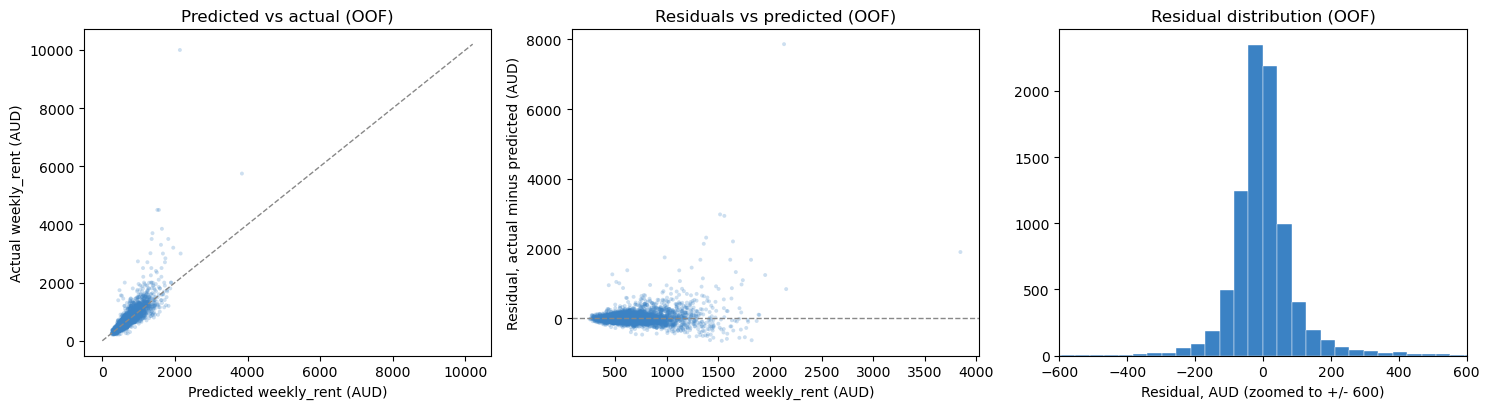


Worst 5 absolute errors (all OOF rows):
  true=$10000  pred=$2136  suburb=TOORAK  type=House  beds=6.0
  true=$4500  pred=$1517  suburb=SOUTH YARRA  type=Apartment / Unit / Flat  beds=3.0
  true=$4500  pred=$1558  suburb=HAWTHORN  type=House  beds=5.0
  true=$3700  pred=$1382  suburb=SOUTH YARRA  type=House  beds=3.0
  true=$3850  pred=$1642  suburb=CREMORNE  type=House  beds=4.0


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

axes[0].scatter(pred_c, true_c, s=8, alpha=0.25, color='#3B82C4', edgecolor='none')
lims = [0, max(true_c.max(), pred_c.max()) * 1.02]
axes[0].plot(lims, lims, color='#888888', linewidth=1, linestyle='--')
axes[0].set_xlabel('Predicted weekly_rent (AUD)')
axes[0].set_ylabel('Actual weekly_rent (AUD)')
axes[0].set_title('Predicted vs actual (OOF)')

axes[1].scatter(pred_c, resid_full, s=8, alpha=0.25, color='#3B82C4', edgecolor='none')
axes[1].axhline(0, color='#888888', linewidth=1, linestyle='--')
axes[1].set_xlabel('Predicted weekly_rent (AUD)')
axes[1].set_ylabel('Residual, actual minus predicted (AUD)')
axes[1].set_title('Residuals vs predicted (OOF)')

axes[2].hist(resid_full, bins=200, color='#3B82C4', edgecolor='white', linewidth=0.3)
axes[2].set_xlim(-600, 600)
axes[2].set_xlabel('Residual, AUD (zoomed to +/- 600)')
axes[2].set_title('Residual distribution (OOF)')

plt.tight_layout()
plt.show()

print('\nWorst 5 absolute errors (all OOF rows):')
worst_idx_in_covered = np.argsort(-np.abs(resid_full))[:5]
covered_row_positions = np.where(covered)[0][worst_idx_in_covered]
for pos in covered_row_positions:
    row = train_df.iloc[pos]
    print(f"  true=${oof_true_dollars[pos]:.0f}  pred=${oof_pred_dollars[pos]:.0f}  "
          f"suburb={row.suburb}  type={row.property_type}  beds={row.bedrooms}")

- **OOF RMSE:** about $160, consistent with the 5-fold mean of $154.6
- **Bias:** mean residual about +$8 on a ~$630 mean rent, essentially unbiased (noise, not systematic skew)
- **Heteroscedasticity:** funnel shape, error variance grows with predicted rent
- **Worst 5 errors:** all severe under-predictions of the ultra-luxury listings flagged in Step 3 (e.g. Toorak $10,000 predicted $2,136; South Yarra $4,500 predicted $1,517)
- **Fold 1 link:** the Toorak listing sits in fold 1's validation slice, which explains its inflated RMSE from Step 9
- **Cause:** genuine model limitation, not leakage or data quality; few training examples above ~$2,500/week, and regularization plus log-target compression pull predictions toward the bulk
- **Caveat:** don't trust the model for high-end/luxury properties
## Step 11 — Feature importance / SHAP

- **Model:** final configuration, tuned `best_params` with `n_estimators` fixed to the mean `best_iteration` across the 5 CV folds (about 814)
- **Training data:** full training set
- **Reuse:** this is the exact model evaluated on the test set in Step 12, so no wasted refit
- **SHAP:** `TreeExplainer` checks that what the model leans on matches domain intuition
- **Compatibility:** native categorical splitting worked cleanly with SHAP

In [17]:
import shap

FINAL_N_ESTIMATORS = int(round(np.mean(tuned_best_iters)))
print('final n_estimators (mean best_iteration across folds):', FINAL_N_ESTIMATORS)

final_model = xgb.XGBRegressor(
    n_estimators=FINAL_N_ESTIMATORS,
    enable_categorical=True,
    tree_method='hist',
    random_state=RANDOM_STATE,
    **best_params,
)
final_model.fit(X_train_full, y_train_full)

explainer = shap.TreeExplainer(final_model)
shap_values = explainer.shap_values(X_train_full)
print('shap_values shape:', shap_values.shape)

final n_estimators (mean best_iteration across folds): 814


shap_values shape: (10398, 94)


                      feature  mean_abs_shap
                     bedrooms       0.097765
                    bathrooms       0.083141
                       suburb       0.067253
       dist_to_cbd_km_driving       0.053917
         median_weekly_income       0.047061
                          lon       0.027494
                    carspaces       0.016958
      beaches_road_distance_m       0.014722
                property_type       0.011903
              feat_dishwasher       0.011880
               feat_furnished       0.009075
           beaches_duration_s       0.006224
                amenity_count       0.005641
                   crime_rate       0.005462
                          lat       0.005379
             days_since_start       0.005298
                   feat_study       0.004419
          feat_secure_parking       0.003899
          feat_balcony___deck       0.002750
park_national_road_distance_m       0.002549


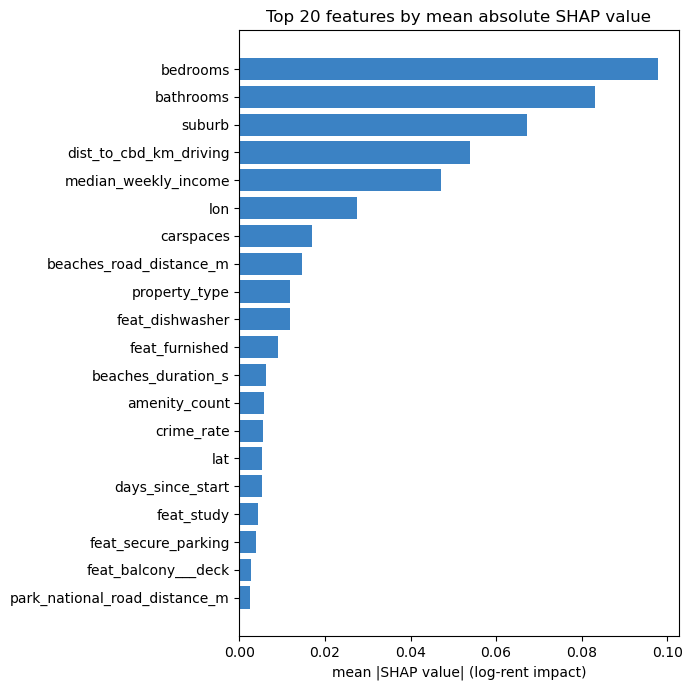

In [18]:
mean_abs_shap = np.abs(shap_values).mean(axis=0)
importance_df = pd.DataFrame({'feature': X_train_full.columns, 'mean_abs_shap': mean_abs_shap}).sort_values('mean_abs_shap', ascending=False)
print(importance_df.head(20).to_string(index=False))

top20 = importance_df.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 7))
ax.barh(top20['feature'], top20['mean_abs_shap'], color='#3B82C4')
ax.set_xlabel('mean |SHAP value| (log-rent impact)')
ax.set_title('Top 20 features by mean absolute SHAP value')
plt.tight_layout()
plt.show()

## Step 12 — Final fit and test evaluation

In [19]:
pred_log_test = final_model.predict(X_test)
pred_dollars_test = np.expm1(pred_log_test)
true_dollars_test = np.expm1(y_test)

test_rmse = rmse(true_dollars_test, pred_dollars_test)
test_mae = mean_absolute_error(true_dollars_test, pred_dollars_test)
test_mape = mape(true_dollars_test, pred_dollars_test)

print(f'TEST SET (n={len(X_test)}, untouched until now):')
print(f'RMSE: ${test_rmse:.1f}')
print(f'MAE : ${test_mae:.1f}')
print(f'MAPE: {test_mape:.1f}%')

print(f'\nFor comparison, CV (Step 9): RMSE {np.mean(tuned_fold_rmse):.1f} +/- {np.std(tuned_fold_rmse):.1f}, '
      f'MAE {np.mean(tuned_fold_mae):.1f} +/- {np.std(tuned_fold_mae):.1f}, '
      f'MAPE {np.mean(tuned_fold_mape):.1f}% +/- {np.std(tuned_fold_mape):.1f}%')
print(f'For comparison, linear baseline (Step 5): RMSE {np.mean(fold_rmse):.1f}, MAE {np.mean(fold_mae):.1f}, MAPE {np.mean(fold_mape):.1f}%')

TEST SET (n=1848, untouched until now):
RMSE: $112.8
MAE : $58.2
MAPE: 8.8%

For comparison, CV (Step 9): RMSE 154.6 +/- 41.4, MAE 68.5 +/- 7.8, MAPE 9.8% +/- 1.0%
For comparison, linear baseline (Step 5): RMSE 215.6, MAE 97.3, MAPE 15.0%


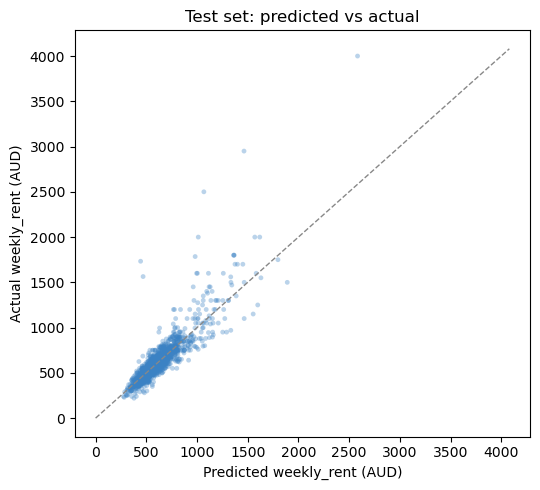

test set max actual rent: $ 4000.0000000000014
test set max predicted rent: $ 2583.0


In [20]:
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(pred_dollars_test, true_dollars_test, s=12, alpha=0.35, color='#3B82C4', edgecolor='none')
lims = [0, max(true_dollars_test.max(), pred_dollars_test.max()) * 1.02]
ax.plot(lims, lims, color='#888888', linewidth=1, linestyle='--')
ax.set_xlabel('Predicted weekly_rent (AUD)')
ax.set_ylabel('Actual weekly_rent (AUD)')
ax.set_title('Test set: predicted vs actual')
plt.tight_layout()
plt.show()

print('test set max actual rent: $', true_dollars_test.max())
print('test set max predicted rent: $', round(pred_dollars_test.max(), 0))

- **Test result (n=1,848, evaluated once):** RMSE $112.8, MAE $58.2, MAPE 8.8%, better than CV (RMSE $154.6, MAE $68.5, MAPE 9.8%)
- **Why better:** final model trained on all 10,398 rows (vs ~5,200 per CV fold), and test's max rent is $4,000, so no Toorak-style outlier inflating RMSE
- **Pattern replicates:** the $4,000 listing is still under-predicted (about $2,583)
- **Vs baseline:** linear regression was RMSE ~$216, MAE ~$97, MAPE ~15.0%
- **Setup:** XGBoost on `log1p(weekly_rent)`, time-based 85/15 split, Optuna (40 trials) over 5-fold `TimeSeriesSplit`
- **Final params:** `learning_rate` ≈ 0.0109, `max_depth` 9, `min_child_weight` ≈ 10.4, `subsample` ≈ 0.81, `colsample_bytree` ≈ 0.70, `n_estimators` 814
- **Top drivers (SHAP):** bedrooms, bathrooms, suburb, distance to CBD, area median income; no leakage signature
- **Caveats:**
  - luxury listings (above ~$2,500/week) are under-predicted
  - 11.5% of test rows share a lat/lon with train, so the score may be slightly inflated
  - upstream zero-missing data was likely backfilled and can't be verified
  - `learning_rate` and `max_depth` sat near search-range edges, so a wider search might help